In [138]:
# import env file, make sure it contains your kaggle token

from dotenv import load_dotenv, find_dotenv
import os

load_dotenv(find_dotenv())   # finds ../.env from notebooks/
print("token loaded:", "KAGGLE_API_TOKEN" in os.environ)

token loaded: False


In [139]:
# download dataset

import kagglehub
from pathlib import Path

DATA_FOLDER = "./../data/raw/"

# Download latest version
if not Path(DATA_FOLDER).exists():
    path = kagglehub.competition_download('favorita-grocery-sales-forecasting', 
                                      output_dir=DATA_FOLDER)

    print("Path to competition files:", path)

In [140]:
# extract files

from pathlib import Path
import py7zr

EXTRACTED_FOLDER = Path(DATA_FOLDER) / "extracted"

if not Path(EXTRACTED_FOLDER).exists():
    folder = Path(DATA_FOLDER)
    for archive in sorted(folder.glob("*.csv.7z")):
        out_dir = archive.with_suffix("")
        print(f"Extracting {archive.name} -> {out_dir.name}")
        try:
            with py7zr.SevenZipFile(archive, mode="r") as z:
                z.extractall(path=EXTRACTED_FOLDER)
        except Exception as e:
            print(f"  Failed: {e}")


In [141]:
# convert train.csv to parquet

import polars as pl

PROCESSED_FOLDER = Path("./../data/processed/")

if not Path(PROCESSED_FOLDER / "train.parquet").exists():
    (
    pl.scan_csv(
        EXTRACTED_FOLDER / "train.csv",
        schema_overrides={
            "store_nbr": pl.Int8,# 1 to 54
            "item_nbr": pl.Int32, # up to ~2.1 million
            "unit_sales": pl.Float32, # decimals
            "onpromotion": pl.Boolean, # True / False / empty
        },
        try_parse_dates=True
    )
    .drop("id")
    .sink_parquet(PROCESSED_FOLDER / "train.parquet", mkdir=True)
    )

train = pl.read_parquet(PROCESSED_FOLDER / "train.parquet")
train.head(800)

date,store_nbr,item_nbr,unit_sales,onpromotion
date,i8,i32,f32,bool
2013-01-01,25,103665,7.0,null
2013-01-01,25,105574,1.0,null
2013-01-01,25,105575,2.0,null
2013-01-01,25,108079,1.0,null
2013-01-01,25,108701,1.0,null
…,…,…,…,…
2013-01-02,1,314881,7.0,null
2013-01-02,1,315176,29.0,null
2013-01-02,1,315178,7.0,null


In [142]:
# read other datafdrames

import pandas as pd

items = pd.read_csv(EXTRACTED_FOLDER / "items.csv")
print(items.head())

transactions = pd.read_csv(EXTRACTED_FOLDER / "transactions.csv")
print(transactions.head())

stores = pd.read_csv(EXTRACTED_FOLDER / "stores.csv")
print(stores.head())

holidays = pd.read_csv(EXTRACTED_FOLDER / "holidays_events.csv")
print(holidays.head())

oil = pd.read_csv(EXTRACTED_FOLDER / "oil.csv")
print(oil.head())

   item_nbr        family  class  perishable
0     96995     GROCERY I   1093           0
1     99197     GROCERY I   1067           0
2    103501      CLEANING   3008           0
3    103520     GROCERY I   1028           0
4    103665  BREAD/BAKERY   2712           1
         date  store_nbr  transactions
0  2013-01-01         25           770
1  2013-01-02          1          2111
2  2013-01-02          2          2358
3  2013-01-02          3          3487
4  2013-01-02          4          1922
   store_nbr           city                           state type  cluster
0          1          Quito                       Pichincha    D       13
1          2          Quito                       Pichincha    D       13
2          3          Quito                       Pichincha    D        8
3          4          Quito                       Pichincha    D        9
4          5  Santo Domingo  Santo Domingo de los Tsachilas    D        4
         date     type    locale locale_name        

# Things to do

* df_train -> wochentag und kalendarmonat als feature erzeugen

* df_train -> mit items verbinden

* stores -> verbinden mit holidays

* df_train -> verbinden mit oil price

* items -> family als class

## Common

* check for outliers

* check for non values

In [198]:
# check test data

test = pd.read_csv(EXTRACTED_FOLDER / "test.csv")
print(test.head())

          id        date  store_nbr  item_nbr  onpromotion
0  125497040  2017-08-16          1     96995        False
1  125497041  2017-08-16          1     99197        False
2  125497042  2017-08-16          1    103501        False
3  125497043  2017-08-16          1    103520        False
4  125497044  2017-08-16          1    103665        False


In [199]:
items.info()
items.describe()
items["family"].nunique()       # check for unique family values                 # no underscore in pandas


<class 'pandas.DataFrame'>
RangeIndex: 4100 entries, 0 to 4099
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   item_nbr    4100 non-null   int64   
 1   family      4100 non-null   category
 2   class       4100 non-null   category
 3   perishable  4100 non-null   int64   
dtypes: category(2), int64(2)
memory usage: 80.5 KB


33

In [200]:
print(items["class"].nunique()) # check for unique class values
print(items.groupby("family")["class"].nunique())  
print(items.groupby("class")["family"].nunique().max())   # should be 1 as a class belongs to one family only, but a family can have multiple classes

337
family
AUTOMOTIVE                     5
BABY CARE                      1
BEAUTY                         9
BEVERAGES                     21
BOOKS                          1
BREAD/BAKERY                  15
CELEBRATION                    4
CLEANING                      26
DAIRY                         22
DELI                          13
EGGS                           3
FROZEN FOODS                  11
GROCERY I                     67
GROCERY II                     1
HARDWARE                       1
HOME AND KITCHEN I            20
HOME AND KITCHEN II           12
HOME APPLIANCES                1
HOME CARE                      6
LADIESWEAR                     1
LAWN AND GARDEN                7
LINGERIE                       3
LIQUOR,WINE,BEER              19
MAGAZINES                      4
MEATS                          5
PERSONAL CARE                 13
PET SUPPLIES                   2
PLAYERS AND ELECTRONICS        1
POULTRY                        3
PREPARED FOODS                10

In [201]:
 #check for unique class values per family

In [202]:
items.isna().sum()                    # missing values per column
items.isna().mean() * 100             # as % of rows

item_nbr      0.0
family        0.0
class         0.0
perishable    0.0
dtype: float64

In [203]:
#convert family and class from string type to category type
items["family"] = items["family"].astype("category")
items["class"] = items["class"].astype("category")

In [204]:
items.info()

<class 'pandas.DataFrame'>
RangeIndex: 4100 entries, 0 to 4099
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   item_nbr    4100 non-null   int64   
 1   family      4100 non-null   category
 2   class       4100 non-null   category
 3   perishable  4100 non-null   int64   
dtypes: category(2), int64(2)
memory usage: 80.5 KB


In [205]:
# convert train to pandas 
train_pd = train.filter(pl.col("date") >= pl.date(2015, 8, 16)).to_pandas()   # convert to pandas for plotting, filter to last pl.date(2015, 8, 16)



In [206]:
# merging items with train_pd 
# check for dublicate items nbr in items (shall appear only once) important before merging with train_pd otherwise dimension problems will occur
items["item_nbr"].duplicated().sum()

rows_before = len(train_pd)
train_pd = train_pd.merge(items, on="item_nbr", how="left") #merge train_pd with items on item_nbr, left join to keep all rows in train_pd
rows_after = len(train_pd)
print(f"Rows before merge: {rows_before}, Rows after merge: {rows_after}") #check if rows are the same, otherwise there are duplicates in items


Rows before merge: 71453276, Rows after merge: 71453276


In [207]:
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   store_nbr  54 non-null     int64   
 1   city       54 non-null     category
 2   state      54 non-null     category
 3   type       54 non-null     category
 4   cluster    54 non-null     category
dtypes: category(4), int64(1)
memory usage: 1.7 KB


In [208]:
stores.describe()

,store_nbr
count,54.000000
mean,27.500000
std,15.732133
min,1.000000
25%,14.250000
50%,27.500000
75%,40.750000
max,54.000000


In [209]:
stores.isna().sum()    
stores.isna().mean() * 100   

store_nbr    0.0
city         0.0
state        0.0
type         0.0
cluster      0.0
dtype: float64

In [210]:
stores["store_nbr"].duplicated().sum()  

np.int64(0)

In [211]:
stores.nunique()

store_nbr    54
city         22
state        16
type          5
cluster      17
dtype: int64

In [212]:
stores["type"].value_counts()


type
D    18
C    15
A     9
B     8
E     4
Name: count, dtype: int64

In [213]:
stores["city"].value_counts()   

city
Quito            18
Guayaquil         8
Cuenca            3
Santo Domingo     3
Ambato            2
Latacunga         2
Machala           2
Manta             2
Babahoyo          1
Cayambe           1
Daule             1
El Carmen         1
Esmeraldas        1
Guaranda          1
Ibarra            1
Libertad          1
Loja              1
Playas            1
Puyo              1
Quevedo           1
Riobamba          1
Salinas           1
Name: count, dtype: int64

In [214]:
#  Hierarchy clean? Each city in only one state?
stores.groupby("city")["state"].nunique().max()   # should be 1

np.int64(1)

In [215]:
for col in ["city", "state", "type", "cluster"]:
    stores[col] = stores[col].astype("category")

rows_before = len(train_pd)
train_pd = train_pd.merge(stores, on="store_nbr", how="left")
print(rows_before, len(train_pd))              # must be equal

71453276 71453276


In [216]:
train_pd.info()

<class 'pandas.DataFrame'>
RangeIndex: 71453276 entries, 0 to 71453275
Data columns (total 12 columns):
 #   Column       Dtype         
---  ------       -----         
 0   date         datetime64[ms]
 1   store_nbr    int8          
 2   item_nbr     int32         
 3   unit_sales   float32       
 4   onpromotion  bool          
 5   family       category      
 6   class        category      
 7   perishable   int64         
 8   city         category      
 9   state        category      
 10  type         category      
 11  cluster      category      
dtypes: bool(1), category(6), datetime64[ms](1), float32(1), int32(1), int64(1), int8(1)
memory usage: 2.2 GB


<class 'pandas.DataFrame'>
RangeIndex: 83488 entries, 0 to 83487
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          83488 non-null  datetime64[us]
 1   store_nbr     83488 non-null  int64         
 2   transactions  83488 non-null  int64         
dtypes: datetime64[us](1), int64(2)
memory usage: 1.9 MB


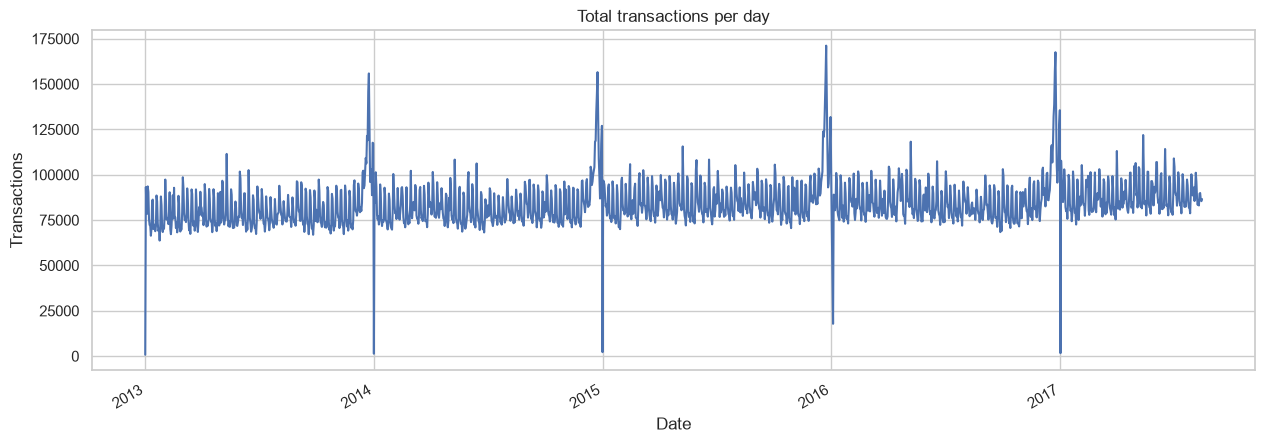

In [217]:
transactions.info()
transactions.describe()
plots = transactions.groupby("date")["transactions"].sum().plot(figsize=(15, 5), title="Total transactions per day", xlabel="Date", ylabel="Transactions")

In [218]:
transactions.isna().mean() * 100   
transactions.head()

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [ ]:
transactions["date"] = pd.to_datetime(transactions["date"]) #convert date column to datetime type
print(transactions.duplicated(subset=["date", "store_nbr"]).sum())   # must be 0 check fpr duplicates in transactions, there should be no duplicates for date and store_nbr

# create average transactions per store per day
avg_transactions = transactions.groupby("store_nbr")["transactions"].mean().reset_index()
#to merge with train_pd we need to wait for train validatio split, as we only want to use the training data to calculate the average transactions per store


0


In [220]:
oil.info()

<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       1704 non-null   datetime64[us]
 1   oil_price  1704 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 26.8 KB


In [221]:
oil["date"] = pd.to_datetime(oil["date"]) #convert date column to datetime type


In [222]:
# make a row for EVERY day, then fill gaps with the last known price
all_days = pd.DataFrame({"date": pd.date_range(oil["date"].min(), oil["date"].max())}) #make 
oil = all_days.merge(oil, on="date", how="left")

oil["dcoilwtico"] = oil["dcoilwtico"].ffill().bfill() # fill missing values with the last known price, forward fill and backward fill to cover all gaps Why both, and in this order? ffill() handles almost everything. It fails only when the very first row is empty, because there’s no earlier value to copy. In Favorita, the first oil day (1 Jan 2013) is empty, so bfill() fills that one cell with the next known price.
oil = oil.rename(columns={"dcoilwtico": "oil_price"}) # rename column to oil_price for clarity
oil.head()


KeyError: 'dcoilwtico'

In [ ]:
train_pd = train_pd.merge(oil, on="date", how="left")

In [ ]:
train_pd.info()
train_pd["oil_price"].isna().sum()   # should be 0

<class 'pandas.DataFrame'>
RangeIndex: 71453276 entries, 0 to 71453275
Data columns (total 13 columns):
 #   Column       Dtype         
---  ------       -----         
 0   date         datetime64[us]
 1   store_nbr    int8          
 2   item_nbr     int32         
 3   unit_sales   float32       
 4   onpromotion  bool          
 5   family       category      
 6   class        category      
 7   perishable   int64         
 8   city         category      
 9   state        category      
 10  type         category      
 11  cluster      category      
 12  oil_price    float64       
dtypes: bool(1), category(6), datetime64[us](1), float32(1), float64(1), int32(1), int64(1), int8(1)
memory usage: 2.7 GB


np.int64(0)

In [ ]:
holidays["date"] = pd.to_datetime(holidays["date"]) #convert date column to datetime type


national = holidays[(holidays["locale"] == "National") & (holidays["transferred"] == False)] #The filter keeps only real national holidays. drop_duplicates makes the date unique. After the merge, non-holidays are NaN, and fillna(0) turns them into 0. Regional and local holidays (matched via the store’s state and city) are a good layer-2 step later.
national = national[["date"]].drop_duplicates()     # one row per date!
national["is_national_holiday"] = 1 

rows_before = len(train_pd) 
train_pd = train_pd.merge(national, on="date", how="left")
train_pd["is_national_holiday"] = train_pd["is_national_holiday"].fillna(0).astype("int8")
print(rows_before, len(train_pd))                   # must be equal

71453276 71453276


In [ ]:
#convert onpromotion from boolean to int8, fill missing values with 0
print(train_pd["onpromotion"].isna().sum())       # probably 0 for 2017
train_pd["onpromotion"] = train_pd["onpromotion"].fillna(False).astype("int8")

train_pd.info()


0
<class 'pandas.DataFrame'>
RangeIndex: 71453276 entries, 0 to 71453275
Data columns (total 14 columns):
 #   Column               Dtype         
---  ------               -----         
 0   date                 datetime64[us]
 1   store_nbr            int8          
 2   item_nbr             int32         
 3   unit_sales           float32       
 4   onpromotion          int8          
 5   family               category      
 6   class                category      
 7   perishable           int64         
 8   city                 category      
 9   state                category      
 10  type                 category      
 11  cluster              category      
 12  oil_price            float64       
 13  is_national_holiday  int8          
dtypes: category(6), datetime64[us](1), float32(1), float64(1), int32(1), int64(1), int8(3)
memory usage: 2.8 GB


In [ ]:
train.head()

date,store_nbr,item_nbr,unit_sales,onpromotion
date,i8,i32,f32,bool
2013-01-01,25,103665,7.0,null
2013-01-01,25,105574,1.0,null
2013-01-01,25,105575,2.0,null
2013-01-01,25,108079,1.0,null
2013-01-01,25,108701,1.0,null


In [ ]:
# 1. Build the grid from the raw sales (code from before)
sales = train.filter(pl.col("date") >= pl.date(2017, 5, 1)).to_pandas()
dates = pd.DataFrame({"date": pd.date_range(sales["date"].min(), sales["date"].max())})
pairs = sales[["store_nbr", "item_nbr"]].drop_duplicates()
grid = dates.merge(pairs, how="cross")
grid = grid.merge(sales, on=["date", "store_nbr", "item_nbr"], how="left")
grid["unit_sales"] = grid["unit_sales"].fillna(0).clip(lower=0)
grid["onpromotion"] = grid["onpromotion"].fillna(False).astype("int8")

# 2. Re-attach the lookup tables you already prepared
rows = len(grid)
grid = grid.merge(items, on="item_nbr", how="left")
grid = grid.merge(stores, on="store_nbr", how="left")
grid = grid.merge(oil, on="date", how="left")
grid = grid.merge(national, on="date", how="left")
grid["is_national_holiday"] = grid["is_national_holiday"].fillna(0).astype("int8")

print(rows == len(grid))                 # must be True
print(grid.isna().sum())                 # check for gaps

train_pd = grid                          # replaces the old version

True
date                   0
store_nbr              0
item_nbr               0
unit_sales             0
onpromotion            0
family                 0
class                  0
perishable             0
city                   0
state                  0
type                   0
cluster                0
oil_price              0
is_national_holiday    0
dtype: int64


In [ ]:
train_pd.info()

<class 'pandas.DataFrame'>
RangeIndex: 17103629 entries, 0 to 17103628
Data columns (total 14 columns):
 #   Column               Dtype         
---  ------               -----         
 0   date                 datetime64[us]
 1   store_nbr            int8          
 2   item_nbr             int32         
 3   unit_sales           float32       
 4   onpromotion          int8          
 5   family               category      
 6   class                category      
 7   perishable           int64         
 8   city                 category      
 9   state                category      
 10  type                 category      
 11  cluster              category      
 12  oil_price            float64       
 13  is_national_holiday  int8          
dtypes: category(6), datetime64[us](1), float32(1), float64(1), int32(1), int64(1), int8(3)
memory usage: 685.1 MB


In [ ]:
def add_date_features(df):
    df["weekday"] = df["date"].dt.dayofweek.astype("int8")      # 0 = Mon … 6 = Sun
    df["day"] = df["date"].dt.day.astype("int8")                # 1 … 31
    df["month"] = df["date"].dt.month.astype("int8")            # 1 … 12
    df["is_weekend"] = (df["weekday"] >= 5).astype("int8")      # Sat/Sun = 1
    df["is_payday"] = ((df["day"] == 15) | df["date"].dt.is_month_end).astype("int8")
    return df

train_pd = add_date_features(train_pd)

/var/folders/by/3zkl4d6n5qg2j8vr2mgw38jr0000gn/T/ipykernel_23699/2908015432.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["weekday"] = df["date"].dt.dayofweek.astype("int8")      # 0 = Mon … 6 = Sun


In [ ]:
train_pd.info(). #### train_pd has all combined tables

<class 'pandas.DataFrame'>
RangeIndex: 17103629 entries, 0 to 17103628
Data columns (total 19 columns):
 #   Column               Dtype         
---  ------               -----         
 0   date                 datetime64[us]
 1   store_nbr            int8          
 2   item_nbr             int32         
 3   unit_sales           float32       
 4   onpromotion          int8          
 5   family               category      
 6   class                category      
 7   perishable           int64         
 8   city                 category      
 9   state                category      
 10  type                 category      
 11  cluster              category      
 12  oil_price            float64       
 13  is_national_holiday  int8          
 14  weekday              int8          
 15  day                  int8          
 16  month                int8          
 17  is_weekend           int8          
 18  is_payday            int8          
dtypes: category(6), datetime64[us]

In [ ]:
#### plots 


import matplotlib.pyplot as plt     # basic plotting
import seaborn as sns               # nicer statistical plots
import numpy as np

sns.set_theme(style="whitegrid")
df = train_pd                     # EDA only on training data
df["weekday"] = df["date"].dt.dayofweek
df["day"] = df["date"].dt.day

/var/folders/by/3zkl4d6n5qg2j8vr2mgw38jr0000gn/T/ipykernel_23699/1540553075.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["weekday"] = df["date"].dt.dayofweek


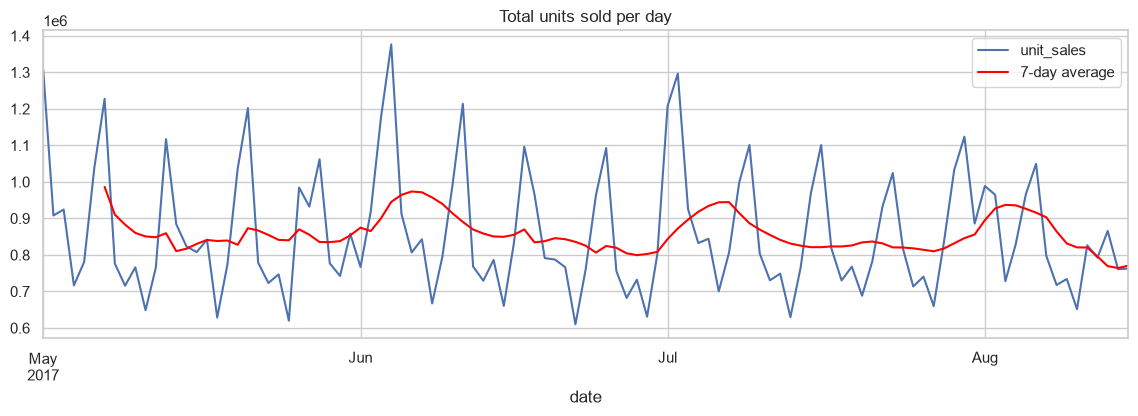

In [ ]:
#Total sales per day: trend and rhythm

daily = df.groupby("date")["unit_sales"].sum()

plt.figure(figsize=(14, 4))
daily.plot()
daily.rolling(7).mean().plot(color="red", label="7-day average")
plt.title("Total units sold per day"); plt.legend(); plt.show()

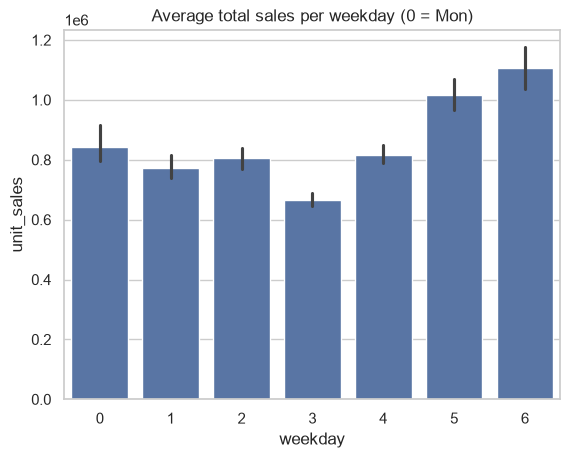

In [ ]:
#Weekends are usually much higher. weekend effect
sns.barplot(x="weekday", y="unit_sales", data=df.groupby(["date", "weekday"])["unit_sales"].sum().reset_index())
plt.title("Average total sales per weekday (0 = Mon)"); plt.show()

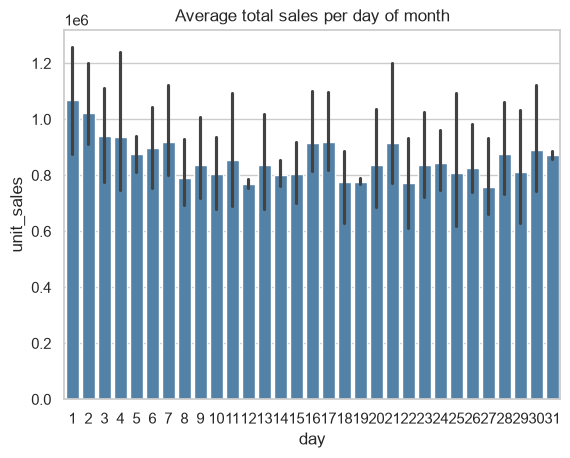

In [ ]:
#Day of month: payday effect
by_day = df.groupby(["date", "day"])["unit_sales"].sum().reset_index()
sns.barplot(x="day", y="unit_sales", data=by_day, color="steelblue")
plt.title("Average total sales per day of month"); plt.show()

Share of zero rows: 33.8 %


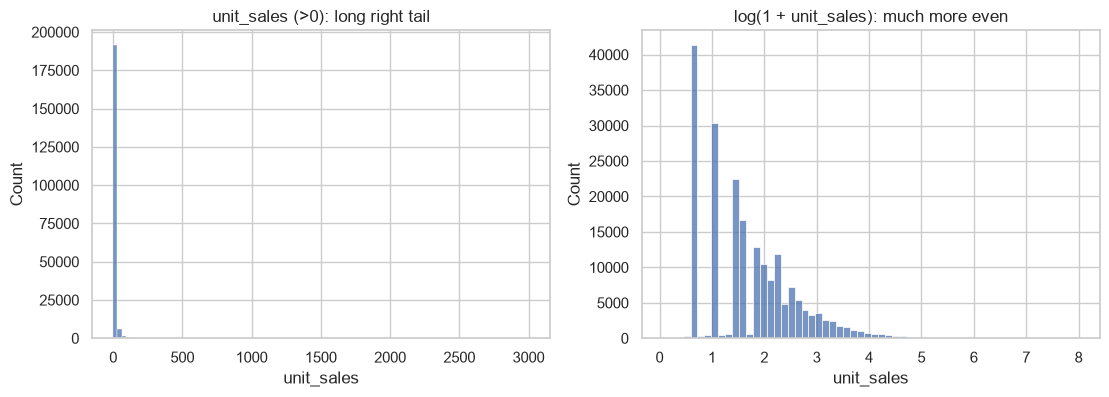

In [ ]:
#Distribution of unit_sales: the zeros

print("Share of zero rows:", round((df["unit_sales"] == 0).mean() * 100, 1), "%")

sold = df[df["unit_sales"] > 0]["unit_sales"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(sold.sample(200_000, random_state=0), bins=100, ax=ax[0])
ax[0].set_title("unit_sales (>0): long right tail")
sns.histplot(np.log1p(sold.sample(200_000, random_state=0)), bins=60, ax=ax[1])
ax[1].set_title("log(1 + unit_sales): much more even"); plt.show()

# WHY LOG?
# Sales per row range from 0 to thousands: a few items sell a LOT, most sell little.
# Without log, the model focuses on the big sellers and ignores the many small ones.
# log1p(x) = log(1 + x) squeezes big numbers together:
#   0 -> 0 | 10 -> 2.4 | 100 -> 4.6 | 1000 -> 6.9
# Now "5 instead of 10" and "500 instead of 1000" count as the same mistake (both half).
# Bonus: a promotion doubling sales is the SAME step for milk and for spices.
# log1p (not log) because log(0) is impossible, and we have many zeros.
# The competition metric (NWRMSLE) is also measured on log1p, so we train on the same scale.
#
# RECIPE:
#   1. y_train = np.log1p(unit_sales)       # train on log values
#   2. pred_log = model.predict(X)          # model predicts log values
#   3. pred = np.expm1(pred_log)            # convert back to real units! (never forget)

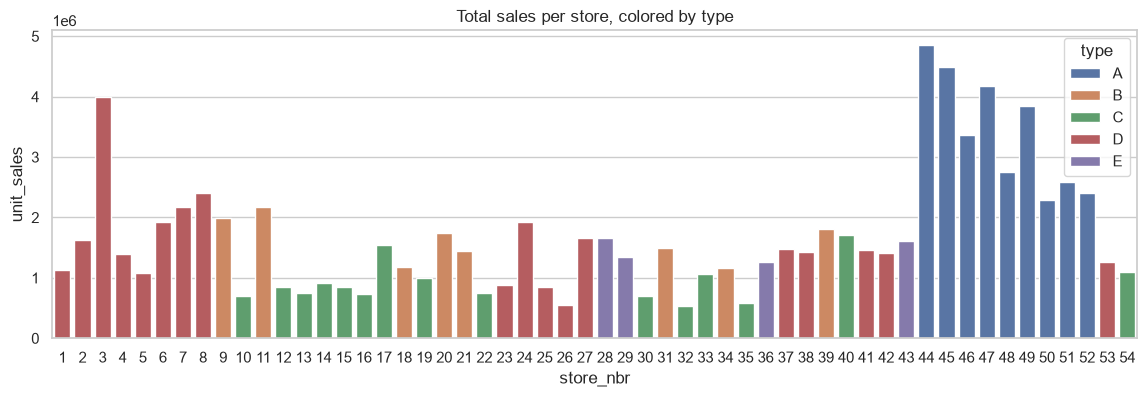

In [ ]:
#Sales per store and store type
store_sales = df.groupby(["store_nbr", "type"], observed=True)["unit_sales"].sum().reset_index()
plt.figure(figsize=(14, 4))
sns.barplot(x="store_nbr", y="unit_sales", hue="type", data=store_sales, dodge=False)
plt.title("Total sales per store, colored by type"); plt.show()

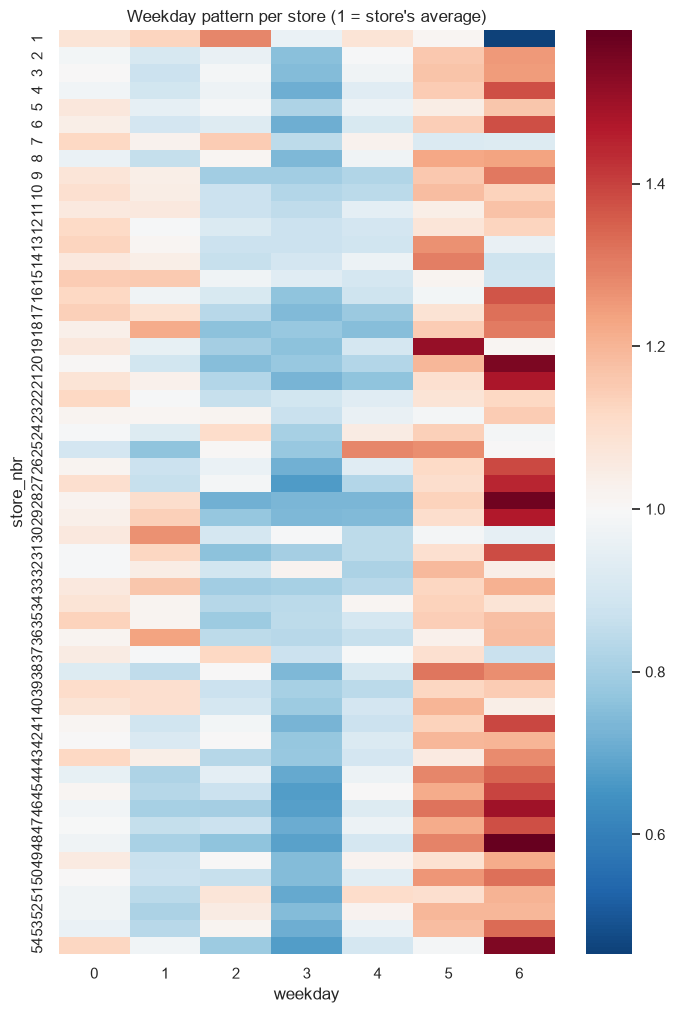

In [ ]:
pivot = df.groupby(["store_nbr", "weekday"])["unit_sales"].sum().unstack()
pivot = pivot.div(pivot.mean(axis=1), axis=0)          # each store relative to its own average
plt.figure(figsize=(8, 12))
sns.heatmap(pivot, cmap="RdBu_r", center=1)
plt.title("Weekday pattern per store (1 = store's average)"); plt.show()

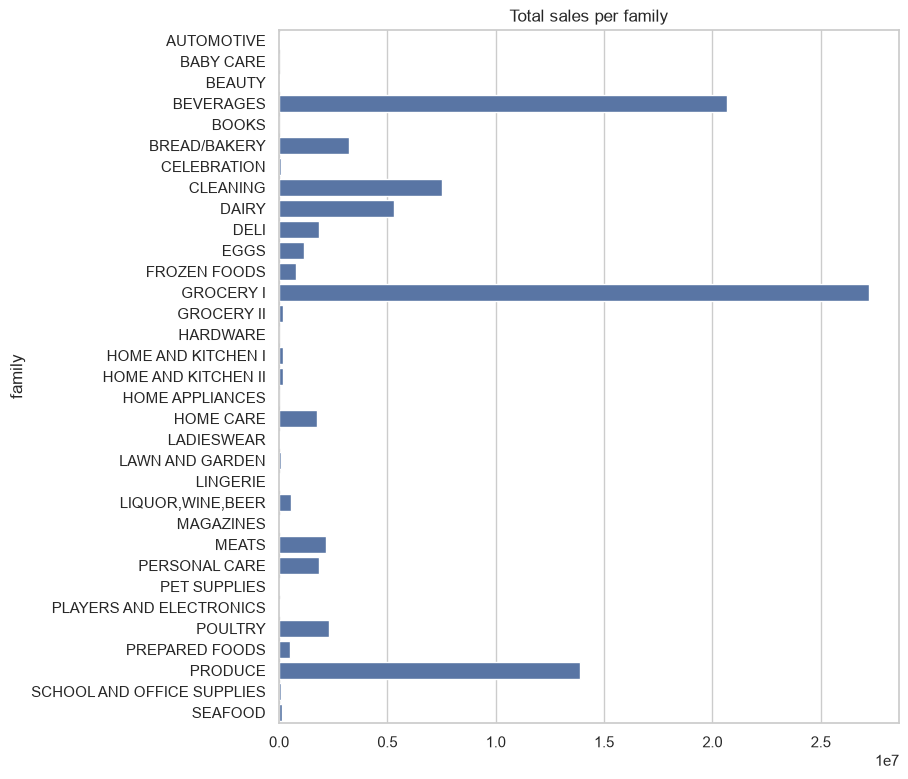

In [ ]:
fam = df.groupby("family", observed=True)["unit_sales"].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 9))
sns.barplot(x=fam.values, y=fam.index)
plt.title("Total sales per family"); plt.show()

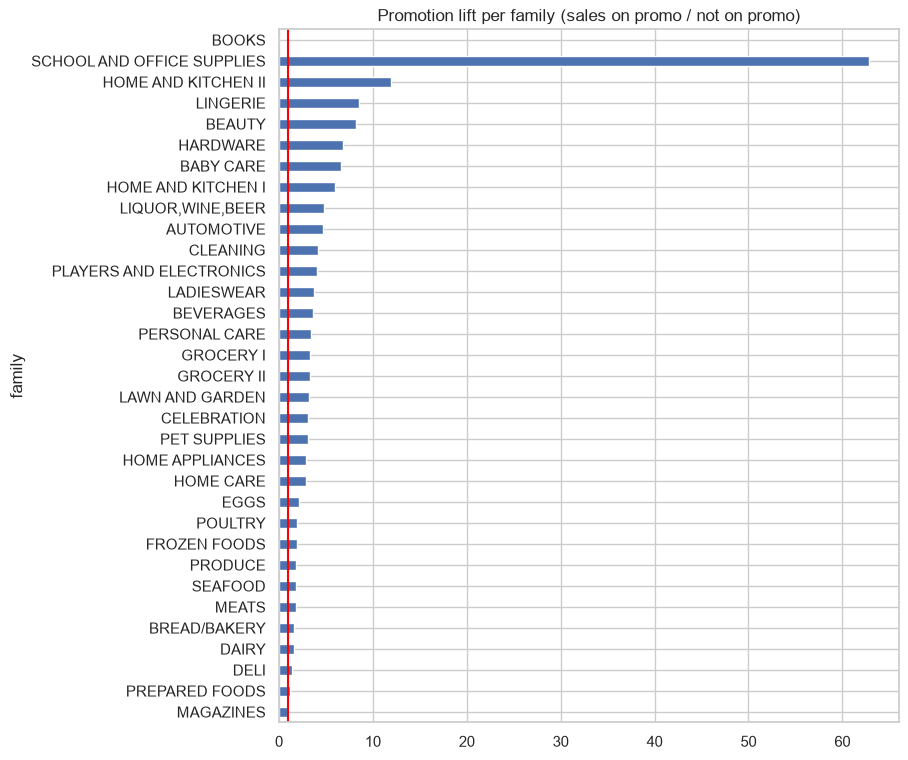

In [ ]:
#. Promotion effect

promo = df.groupby(["family", "onpromotion"], observed=True)["unit_sales"].mean().unstack()
promo["lift"] = promo[1] / promo[0]
promo["lift"].sort_values().plot(kind="barh", figsize=(8, 9))
plt.axvline(1, color="red"); plt.title("Promotion lift per family (sales on promo / not on promo)"); plt.show()

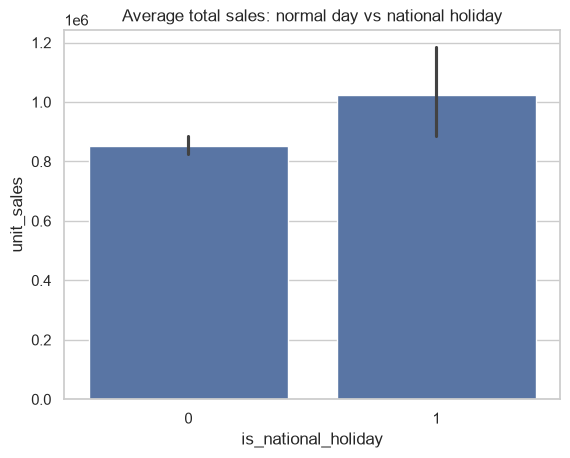

In [ ]:
#holidays: national vs normal day
sns.barplot(x="is_national_holiday", y="unit_sales",
            data=df.groupby(["date", "is_national_holiday"])["unit_sales"].sum().reset_index())
plt.title("Average total sales: normal day vs national holiday"); plt.show()

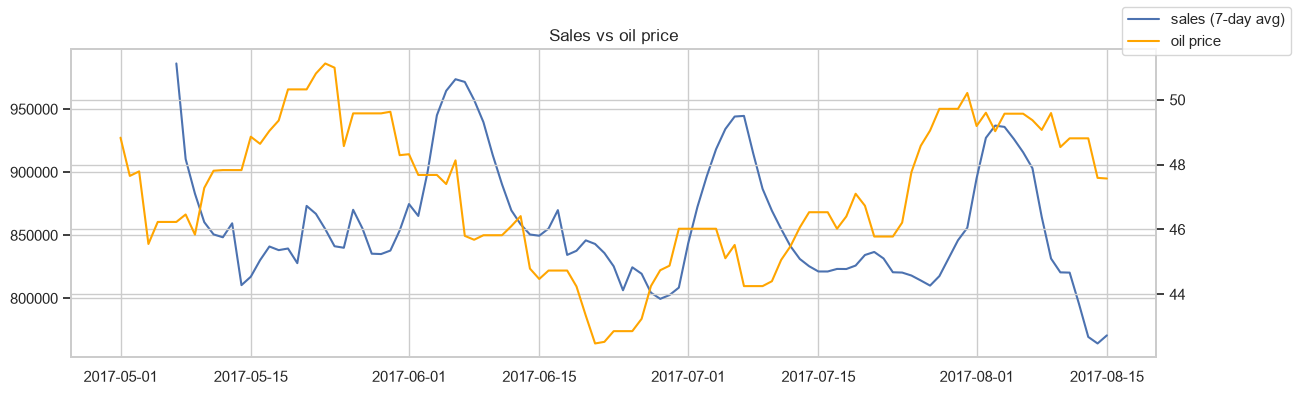

In [ ]:
#. Oil price vs sales
d = df.groupby("date").agg(sales=("unit_sales", "sum"), oil=("oil_price", "first"))
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(d.index, d["sales"].rolling(7).mean(), label="sales (7-day avg)")
ax2 = ax1.twinx()                                  # second y-axis on the right
ax2.plot(d.index, d["oil"], color="orange", label="oil price")
plt.title("Sales vs oil price"); fig.legend(); plt.show()

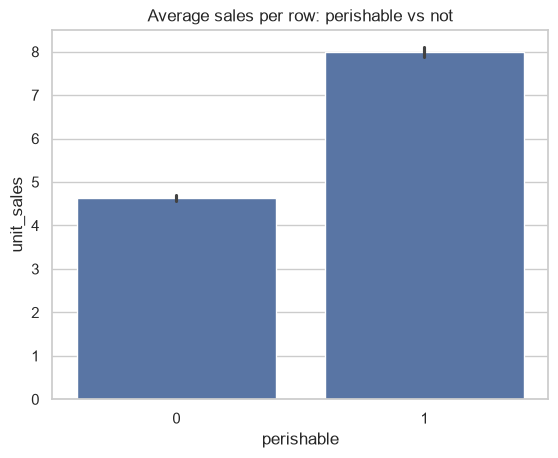

In [ ]:
#. Perishable vs not
sns.barplot(x="perishable", y="unit_sales", data=df.sample(500_000, random_state=0))
plt.title("Average sales per row: perishable vs not"); plt.show()

Every plot must answer a question (“Is there a weekly pattern?”). Write the answer down in a markdown cell below the plot. That’s your EDA report and your feature list.
Plot 4 is the most important: zeros and the long tail mean you should train on log1p(unit_sales) and convert back with np.expm1 at the end.
Aggregated plots show averages. Single items can behave very differently. Look at 2–3 example items too:

In [225]:
train_pd.to_parquet("../data/processed/train_clean.parquet", index=False)
transactions.to_parquet("../data/processed/transactions.parquet", index=False)